# BankChurners Exploratory Analysis and KPI Development
## Task 3

I use the cleaned BankChurners dataset from Task 2 to examine customer attrition. I calculate portfolio and segment KPIs, compare existing and attrited customers, identify recorded behaviour patterns, and create a simple retention review score.

### Main findings
- The file contains 10,127 customers, including 1,627 labelled attrited (16.07%).
- Customers with fewer than 50 transactions have 38.00% recorded attrition, compared with 1.32% among customers with 80 or more transactions.
- Zero recorded utilisation is associated with 36.15% attrition, but the timing of this measurement relative to leaving is uncertain.
- My three-rule score assigns 1,384 existing customers to the High review band. This is a review priority, not a validated probability of future churn.

### Scope and assumptions
I use the supplied cleaned file, preserving its six derived fields. The outcome is Churn_Flag: 1 means attrited and 0 means existing. Percentages use customers within the relevant group as the denominator. I keep Unknown income as its own segment and report small group sizes.

The file is a customer snapshot. I cannot establish a rising attrition trend, causal reasons for leaving, or an annual retention rate. Transaction amounts retain the source monetary units and are not bank revenue. I do not assume this sample represents a particular country.

### Libraries
I use pandas for calculations, matplotlib for charts, and pathlib for file locations. I use short code cells, explain their purpose, and interpret the displayed results in my own words.

## 1 Import libraries

I import the tools used to read the data, calculate tables, and draw charts.

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path
from IPython.display import display

pd.set_option('display.max_columns', 15)
pd.set_option('display.width', 160)
plt.rcParams.update({'font.size': 11, 'axes.spines.top': False, 'axes.spines.right': False})
print('Libraries imported successfully.')

Libraries imported successfully.


**My interpretation**

The libraries are ready. No machine-learning library is needed because I use an explicit rule-based score.

## 2 Load the cleaned dataset

I read the prepared CSV into dl. I retain CLIENTNUM as text and create a separate folder for Task 3 outputs.

In [2]:
file_path = Path(r"/workspace/scratch/8d55d39321ed/upload/BankChurners_Cleaned (1).csv")
dl = pd.read_csv(file_path, dtype={'CLIENTNUM': str})
source_dl = dl.copy(deep=True)
output_folder = file_path.parent / 'Task3_Outputs'
output_folder.mkdir(exist_ok=True)

print('Customer records:', dl.shape[0])
print('Columns:', dl.shape[1])
# Preview customer attributes without displaying identifiers.
display(dl.drop(columns='CLIENTNUM').head())

Customer records: 10127
Columns: 27


,Attrition_Flag,Customer_Age,Gender,Dependent_count,Education_Level,Marital_Status,Income_Category,...,Avg_Utilization_Ratio,Age_Band,Income_Segment,Utilization_Category,Transaction_Frequency_Category,Churn_Flag,Has_Unknown_Demographics
0,Existing Customer,45,M,3,High School,Married,$60K - $80K,...,0.061,45 to 54,$40K to below $80K,Low,Low,0,0
1,Existing Customer,49,F,5,Graduate,Single,Less than $40K,...,0.105,45 to 54,Below $40K,Low,Low,0,0
2,Existing Customer,51,M,3,Graduate,Married,$80K - $120K,...,0.000,45 to 54,$80K and above,Zero,Low,0,0
3,Existing Customer,40,F,4,High School,Unknown,Less than $40K,...,0.760,35 to 44,Below $40K,High,Low,0,1
4,Existing Customer,40,M,3,Uneducated,Married,$60K - $80K,...,0.000,35 to 44,$40K to below $80K,Zero,Low,0,0


**My interpretation**

The cleaned file contains 10,127 customers and 27 columns. Age bands, income segments, utilisation groups, transaction groups, and the recorded churn flag are already available from Task 2.

## 3 Verify the input

I make a few checks before calculating KPIs. Assertions stop execution if the required conditions are not met.

In [3]:
required_fields = [
    'CLIENTNUM', 'Attrition_Flag', 'Churn_Flag', 'Total_Trans_Ct',
    'Total_Trans_Amt', 'Credit_Limit', 'Avg_Utilization_Ratio',
    'Months_Inactive_12_mon', 'Total_Relationship_Count',
    'Contacts_Count_12_mon', 'Age_Band', 'Income_Segment',
    'Utilization_Category', 'Transaction_Frequency_Category'
]
assert all(column in dl.columns for column in required_fields)
assert dl['CLIENTNUM'].is_unique
assert dl[required_fields].notna().all().all()
assert dl['Churn_Flag'].isin([0, 1]).all()
assert dl['Churn_Flag'].equals(dl['Attrition_Flag'].map({'Existing Customer': 0, 'Attrited Customer': 1}))
assert not any(column.startswith('Naive_Bayes_Classifier_') for column in dl.columns)
print('Input checks passed.')

Input checks passed.


**My interpretation**

Customer identifiers are unique, required fields are populated, the outcome matches its source label, and the two classifier outputs are absent. Unknown demographic categories remain explicit; passing these checks does not independently verify the data source.

## 4 Define the portfolio KPIs

I define each measure before calculating it. This avoids confusing customer activity, bank revenue, and recorded customer status.

In [4]:
kpi_definitions = pd.DataFrame({
    'KPI': ['Total customers', 'Attrited customers', 'Attrition proportion',
            'Existing customer proportion', 'Average credit limit',
            'Average utilisation', 'Recorded transaction amount',
            'Average transaction count', 'Average product relationships'],
    'Definition': ['Distinct customer IDs', 'Customers with Churn_Flag = 1',
        'Attrited customers divided by all customers, times 100',
        'Existing customers divided by all customers, times 100',
        'Mean Credit_Limit in original units',
        'Mean Avg_Utilization_Ratio, times 100', 'Sum of Total_Trans_Amt in original units',
        'Mean Total_Trans_Ct', 'Mean Total_Relationship_Count']
})
display(kpi_definitions)

,KPI,Definition
0,Total customers,Distinct customer IDs
1,Attrited customers,Customers with Churn_Flag = 1
2,Attrition proportion,"Attrited customers divided by all customers, t..."
3,Existing customer proportion,"Existing customers divided by all customers, t..."
4,Average credit limit,Mean Credit_Limit in original units
5,Average utilisation,"Mean Avg_Utilization_Ratio, times 100"
6,Recorded transaction amount,Sum of Total_Trans_Amt in original units
7,Average transaction count,Mean Total_Trans_Ct
8,Average product relationships,Mean Total_Relationship_Count


**My interpretation**

Existing customer proportion is a status measure, not an active-customer ratio or a measured longitudinal retention rate. Average utilisation gives each customer equal weight. It is not total revolving balance divided by total credit limit.

## 5 Calculate full-dataset KPIs

The mean of a 0/1 flag gives the proportion of records equal to 1. I multiply by 100 to show percentages.

In [5]:
total_customers = len(dl)
attrited_customers = int(dl['Churn_Flag'].sum())
existing_customers = total_customers - attrited_customers
portfolio_attrition = dl['Churn_Flag'].mean() * 100

portfolio_kpis = pd.DataFrame({
    'KPI': kpi_definitions['KPI'],
    'Value': [total_customers, attrited_customers, portfolio_attrition,
        existing_customers / total_customers * 100,
        dl['Credit_Limit'].mean(), dl['Avg_Utilization_Ratio'].mean() * 100,
        dl['Total_Trans_Amt'].sum(), dl['Total_Trans_Ct'].mean(),
        dl['Total_Relationship_Count'].mean()],
    'Unit': ['Customers', 'Customers', 'Percent', 'Percent',
             'Original monetary units', 'Percent', 'Original monetary units',
             'Recorded transactions per customer', 'Relationships per customer']
})
display(portfolio_kpis.round(2))

,KPI,Value,Unit
0,Total customers,10127.00,Customers
1,Attrited customers,1627.00,Customers
2,Attrition proportion,16.07,Percent
3,Existing customer proportion,83.93,Percent
4,Average credit limit,8631.95,Original monetary units
5,Average utilisation,27.49,Percent
6,Recorded transaction amount,44600182.00,Original monetary units
7,Average transaction count,64.86,Recorded transactions per customer
8,Average product relationships,3.81,Relationships per customer


**My interpretation**

Recorded attrition is 16.07%, with 1,627 attrited and 8,500 existing customers. Average credit limit is 8,631.95 original monetary units, average utilisation is 27.49%, average transaction count is 64.86, and average relationship count is 3.81. Total recorded transaction amount is 44,600,182. These figures describe this file, not a confirmed annual reporting period.

## 6 Visualise customer status

A bar chart makes the difference in customer counts visible without exaggerating the smaller group.

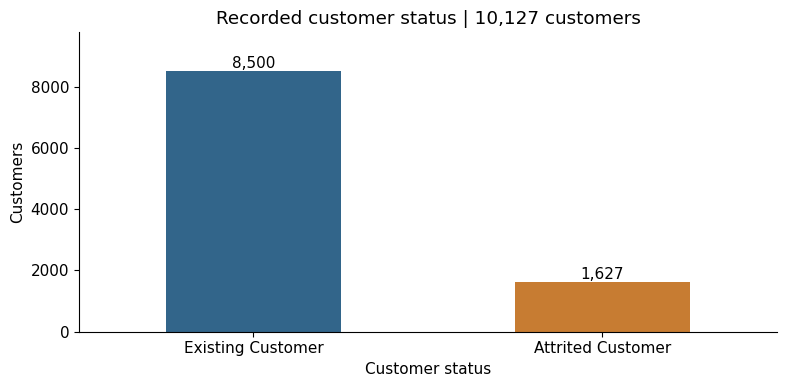

In [6]:
status_counts = dl['Attrition_Flag'].value_counts().reindex(['Existing Customer', 'Attrited Customer'])
ax = status_counts.plot.bar(figsize=(8, 4), color=['#32658a', '#c77c32'], rot=0)
ax.set_title('Recorded customer status | 10,127 customers')
ax.set_xlabel('Customer status')
ax.set_ylabel('Customers')
for position, value in enumerate(status_counts):
    ax.text(position, value + 100, f'{value:,}', ha='center')
ax.set_ylim(0, status_counts.max() * 1.15)
plt.tight_layout()
plt.savefig(output_folder / '01_Customer_Status.png', dpi=150)
plt.show()

**My interpretation**

Existing customers form 83.93% of the sample. This imbalance matters if a predictive model is developed later: labelling everyone existing would achieve 83.93% accuracy while identifying no attrited customers. I therefore do not use accuracy alone to justify a risk indicator.

## 7 Compute summary statistics

I exclude identifiers and outcome flags from summaries of customer measurements. Quartiles and medians help show whether averages hide uneven distributions.

In [7]:
comparison_fields = [
    'Total_Trans_Ct', 'Total_Trans_Amt', 'Avg_Utilization_Ratio',
    'Months_Inactive_12_mon', 'Total_Relationship_Count',
    'Contacts_Count_12_mon', 'Credit_Limit', 'Customer_Age'
]
summary_statistics = dl[comparison_fields].describe().T
display(summary_statistics.round(3))

,count,mean,std,min,25%,50%,75%,max
Total_Trans_Ct,10127.0,64.859,23.473,10.0,45.000,67.000,81.000,139.000
Total_Trans_Amt,10127.0,4404.086,3397.129,510.0,2155.500,3899.000,4741.000,18484.000
Avg_Utilization_Ratio,10127.0,0.275,0.276,0.0,0.023,0.176,0.503,0.999
Months_Inactive_12_mon,10127.0,2.341,1.011,0.0,2.000,2.000,3.000,6.000
Total_Relationship_Count,10127.0,3.813,1.554,1.0,3.000,4.000,5.000,6.000
Contacts_Count_12_mon,10127.0,2.455,1.106,0.0,2.000,2.000,3.000,6.000
Credit_Limit,10127.0,8631.954,9088.777,1438.3,2555.000,4549.000,11067.500,34516.000
Customer_Age,10127.0,46.326,8.017,26.0,41.000,46.000,52.000,73.000


**My interpretation**

Credit limit has a mean of 8,631.95 and a median of 4,549, indicating that high limits pull up the average. Transaction amount has a mean of 4,404.09 and a median of 3,899. I will compare both means and medians by customer status instead of relying on one statistic.

## 8 Compare mean values by customer status

I use groupby to split the records by status, then calculate the same eight measurements for each group. I convert utilisation to percentage units for readability.

In [8]:
status_order = ['Existing Customer', 'Attrited Customer']
mean_comparison = dl.groupby('Attrition_Flag')[comparison_fields].mean().reindex(status_order)
mean_comparison['Avg_Utilization_Ratio'] = mean_comparison['Avg_Utilization_Ratio'] * 100
mean_comparison = mean_comparison.rename(columns={'Avg_Utilization_Ratio': 'Mean_utilisation_percent'})
display(mean_comparison.round(2).T)

Attrition_Flag,Existing Customer,Attrited Customer
Total_Trans_Ct,68.67,44.93
Total_Trans_Amt,4654.66,3095.03
Mean_utilisation_percent,29.64,16.25
Months_Inactive_12_mon,2.27,2.69
Total_Relationship_Count,3.91,3.28
Contacts_Count_12_mon,2.36,2.97
Credit_Limit,8726.88,8136.04
Customer_Age,46.26,46.66


**My interpretation**

Attrited customers average 44.93 transactions compared with 68.67 among existing customers. They average 3,095.03 in transaction amount compared with 4,654.66, and 16.22% utilisation compared with 29.63%. Attrited customers also have more inactive months (2.69 versus 2.27), fewer relationships (3.28 versus 3.91), and more contacts (2.97 versus 2.36). Average ages are close (46.66 versus 46.26), so age alone appears less informative in this comparison. These are unadjusted associations, not causal effects.

## 9 Compare median values

The median is the middle value. It is less affected by high extremes than the mean, so I use it to check the direction of the observed differences.

In [9]:
median_comparison = dl.groupby('Attrition_Flag')[comparison_fields].median().reindex(status_order)
median_comparison['Avg_Utilization_Ratio'] = median_comparison['Avg_Utilization_Ratio'] * 100
median_comparison = median_comparison.rename(columns={'Avg_Utilization_Ratio': 'Median_utilisation_percent'})
display(median_comparison.round(2).T)

Attrition_Flag,Existing Customer,Attrited Customer
Total_Trans_Ct,71.0,43.0
Total_Trans_Amt,4100.0,2329.0
Median_utilisation_percent,21.1,0.0
Months_Inactive_12_mon,2.0,3.0
Total_Relationship_Count,4.0,3.0
Contacts_Count_12_mon,2.0,3.0
Credit_Limit,4643.5,4178.0
Customer_Age,46.0,47.0


**My interpretation**

Median transaction count is 43 among attrited customers and 71 among existing customers. Median transaction amount is 2,329 versus 4,100. Median utilisation is 0% versus 21.1%, and median relationship count is three versus four. The medians broadly support the mean comparisons, while showing that zero utilisation is common among attrited customers.

## 10 Compare distributions visually

Box plots show the median, the middle half of values, and potential extremes. I use separate panels because the four measurements have different units.

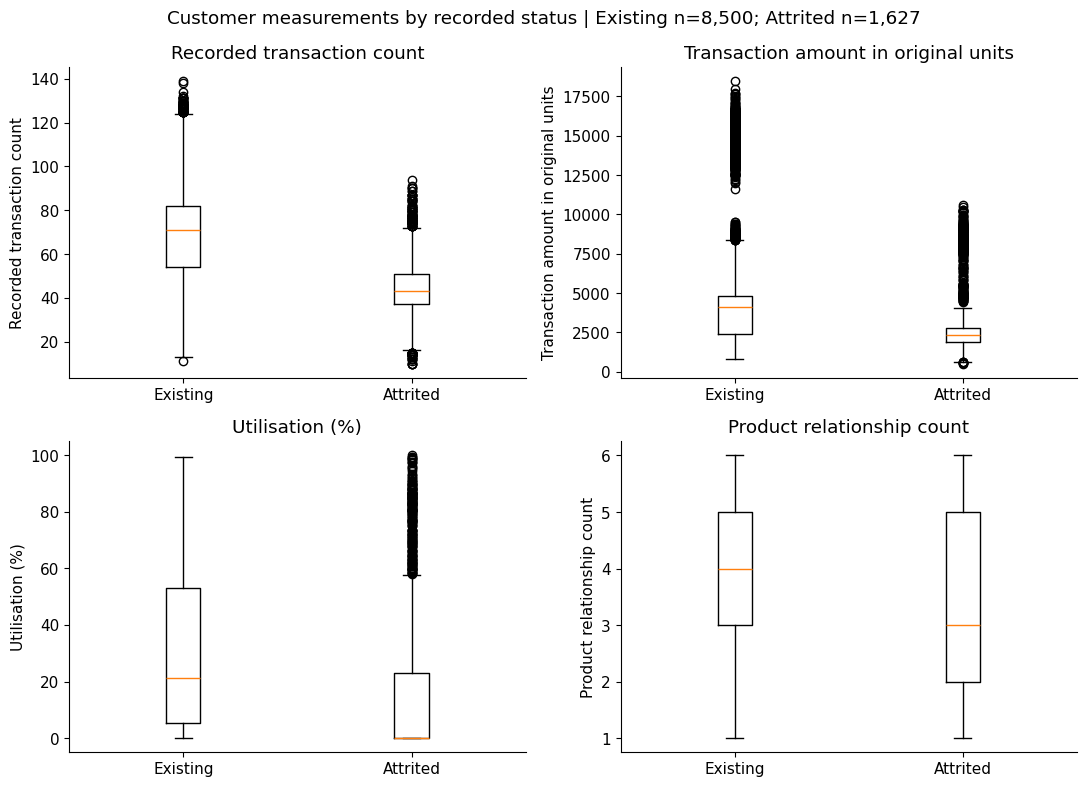

In [10]:
plot_fields = ['Total_Trans_Ct', 'Total_Trans_Amt', 'Avg_Utilization_Ratio', 'Total_Relationship_Count']
plot_labels = ['Recorded transaction count', 'Transaction amount in original units', 'Utilisation (%)', 'Product relationship count']
fig, axes = plt.subplots(2, 2, figsize=(11, 8))
for ax, field, label in zip(axes.flat, plot_fields, plot_labels):
    groups = [dl.loc[dl['Attrition_Flag'] == status, field] for status in status_order]
    if field == 'Avg_Utilization_Ratio':
        groups = [values * 100 for values in groups]
    ax.boxplot(groups)
    ax.set_xticks([1, 2])
    ax.set_xticklabels(['Existing', 'Attrited'])
    ax.set_ylabel(label)
    ax.set_title(label)
fig.suptitle('Customer measurements by recorded status | Existing n=8,500; Attrited n=1,627')
plt.tight_layout()
plt.savefig(output_folder / '02_Status_Distributions.png', dpi=150)
plt.show()

**My interpretation**

The transaction-count and utilisation distributions differ between the two status groups, but still overlap. An individual customer cannot be classified with certainty from a group average or a box plot. Transaction amounts also include high values in both groups, reinforcing the decision to retain valid extremes in Task 2.

## 11 Examine transaction frequency

I calculate the same KPIs within each group. The attrition percentage uses the group customer count as its denominator, so it can be compared across differently sized segments. Monetary measures retain the original units.

,Customers,Attrited,Mean_transactions,Mean_transaction_amount,Mean_credit_limit,Mean_utilisation_percent,Mean_relationships,Attrition_percent
Transaction_Frequency_Category,,,,,,,,
Low,3037,1154,36.48,1797.84,8229.89,26.12,4.02,38.00
Moderate,4367,437,67.03,4027.02,8373.99,28.41,4.10,10.01
High,2723,36,93.03,7915.59,9494.10,27.53,3.11,1.32


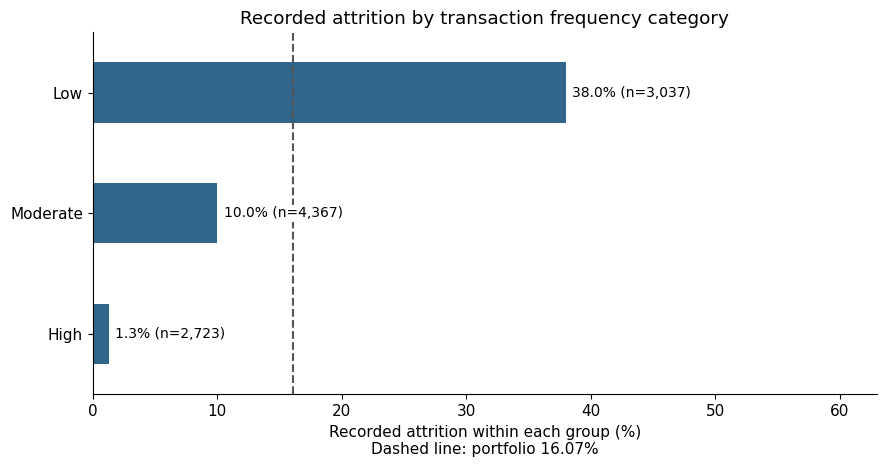

In [11]:
# Group customers and calculate customer counts and segment KPIs.
transaction_segment = dl.groupby('Transaction_Frequency_Category').agg(
    Customers=('Churn_Flag', 'size'),
    Attrited=('Churn_Flag', 'sum'),
    Mean_transactions=('Total_Trans_Ct', 'mean'),
    Mean_transaction_amount=('Total_Trans_Amt', 'mean'),
    Mean_credit_limit=('Credit_Limit', 'mean'),
    Mean_utilisation=('Avg_Utilization_Ratio', 'mean'),
    Mean_relationships=('Total_Relationship_Count', 'mean')
)
transaction_segment = transaction_segment.reindex(['Low', 'Moderate', 'High'])
transaction_segment['Attrition_percent'] = transaction_segment['Attrited'] / transaction_segment['Customers'] * 100
transaction_segment['Mean_utilisation'] = transaction_segment['Mean_utilisation'] * 100
transaction_segment = transaction_segment.rename(columns={'Mean_utilisation': 'Mean_utilisation_percent'})
display(transaction_segment.round(2))

# Compare percentages, keeping customer counts visible in labels.
ax = transaction_segment['Attrition_percent'].plot.barh(figsize=(9, 4.8), color='#32658a')
ax.set_title('Recorded attrition by transaction frequency category')
ax.set_xlabel('Attrited customers within each group (%)')
ax.set_ylabel('')
ax.axvline(portfolio_attrition, color='#555555', linestyle='--', label='Portfolio proportion')
for position, (group, row) in enumerate(transaction_segment.iterrows()):
    ax.text(row['Attrition_percent'] + 0.5, position,
            f"{row['Attrition_percent']:.1f}% (n={int(row['Customers']):,})", va='center', fontsize=10,
            bbox={'facecolor': 'white', 'edgecolor': 'none', 'pad': 1})
ax.set_xlim(0, max(50, transaction_segment['Attrition_percent'].max() + 25))
ax.invert_yaxis()
# The dashed line marks the portfolio attrition proportion.
ax.set_xlabel(f'Recorded attrition within each group (%)\nDashed line: portfolio {portfolio_attrition:.2f}%')
plt.tight_layout()
plt.savefig(output_folder / '03_transaction_segment.png', dpi=150)
plt.show()

**My interpretation**

Low-frequency customers have 1,154 attrited records out of 3,037 (38.00%). Moderate-frequency customers have 437 of 4,367 (10.01%), and High-frequency customers have 36 of 2,723 (1.32%). Lower recorded activity is associated with higher attrition. It could precede leaving, reflect leaving, or share another explanation; this snapshot cannot determine the direction.

## 12 Examine credit utilisation

I calculate the same KPIs within each group. The attrition percentage uses the group customer count as its denominator, so it can be compared across differently sized segments. Monetary measures retain the original units.

,Customers,Attrited,Mean_transactions,Mean_transaction_amount,Mean_credit_limit,Mean_utilisation_percent,Mean_relationships,Attrition_percent
Utilization_Category,,,,,,,,
Zero,2470,893,61.43,4000.15,8039.11,0.00,3.73,36.15
Low,3776,385,66.86,5015.70,14798.37,13.49,3.74,10.20
Moderate,2066,167,66.26,4347.26,3437.35,45.36,3.89,8.08
High,1815,182,63.78,3746.04,2522.85,73.69,3.99,10.03


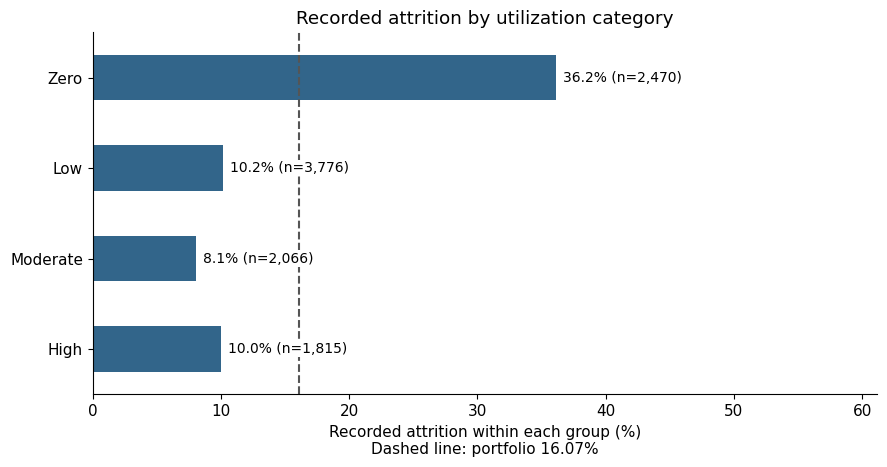

In [12]:
# Group customers and calculate customer counts and segment KPIs.
utilisation_segment = dl.groupby('Utilization_Category').agg(
    Customers=('Churn_Flag', 'size'),
    Attrited=('Churn_Flag', 'sum'),
    Mean_transactions=('Total_Trans_Ct', 'mean'),
    Mean_transaction_amount=('Total_Trans_Amt', 'mean'),
    Mean_credit_limit=('Credit_Limit', 'mean'),
    Mean_utilisation=('Avg_Utilization_Ratio', 'mean'),
    Mean_relationships=('Total_Relationship_Count', 'mean')
)
utilisation_segment = utilisation_segment.reindex(['Zero', 'Low', 'Moderate', 'High'])
utilisation_segment['Attrition_percent'] = utilisation_segment['Attrited'] / utilisation_segment['Customers'] * 100
utilisation_segment['Mean_utilisation'] = utilisation_segment['Mean_utilisation'] * 100
utilisation_segment = utilisation_segment.rename(columns={'Mean_utilisation': 'Mean_utilisation_percent'})
display(utilisation_segment.round(2))

# Compare percentages, keeping customer counts visible in labels.
ax = utilisation_segment['Attrition_percent'].plot.barh(figsize=(9, 4.8), color='#32658a')
ax.set_title('Recorded attrition by utilization category')
ax.set_xlabel('Attrited customers within each group (%)')
ax.set_ylabel('')
ax.axvline(portfolio_attrition, color='#555555', linestyle='--', label='Portfolio proportion')
for position, (group, row) in enumerate(utilisation_segment.iterrows()):
    ax.text(row['Attrition_percent'] + 0.5, position,
            f"{row['Attrition_percent']:.1f}% (n={int(row['Customers']):,})", va='center', fontsize=10,
            bbox={'facecolor': 'white', 'edgecolor': 'none', 'pad': 1})
ax.set_xlim(0, max(50, utilisation_segment['Attrition_percent'].max() + 25))
ax.invert_yaxis()
# The dashed line marks the portfolio attrition proportion.
ax.set_xlabel(f'Recorded attrition within each group (%)\nDashed line: portfolio {portfolio_attrition:.2f}%')
plt.tight_layout()
plt.savefig(output_folder / '04_utilisation_segment.png', dpi=150)
plt.show()

**My interpretation**

Zero utilisation has 893 attrited customers out of 2,470 (36.15%). Low, Moderate, and High utilisation have attrition proportions of 10.20%, 8.08%, and 10.03%. The main distinction is zero utilisation, rather than a steadily increasing pattern across usage levels. Zero balance may follow account closure, so I do not treat it as a proven advance warning.

## 13 Examine inactive months

I calculate the same KPIs within each group. The attrition percentage uses the group customer count as its denominator, so it can be compared across differently sized segments. Monetary measures retain the original units.

,Customers,Attrited,Mean_transactions,Mean_transaction_amount,Mean_credit_limit,Mean_utilisation_percent,Mean_relationships,Attrition_percent
Months_Inactive_12_mon,,,,,,,,
0,29,15,54.41,3156.34,7014.27,15.45,3.97,51.72
1,2233,100,67.27,4672.82,8628.31,28.75,3.83,4.48
2,3282,505,64.98,4401.07,8925.32,27.11,3.81,15.39
3,3846,826,63.71,4321.20,8561.65,27.06,3.78,21.48
4,435,130,60.67,3769.31,7916.64,26.82,3.93,29.89
5,178,32,67.78,4688.28,7515.52,31.08,3.76,17.98
6,124,19,66.91,4326.02,7603.88,28.13,3.87,15.32


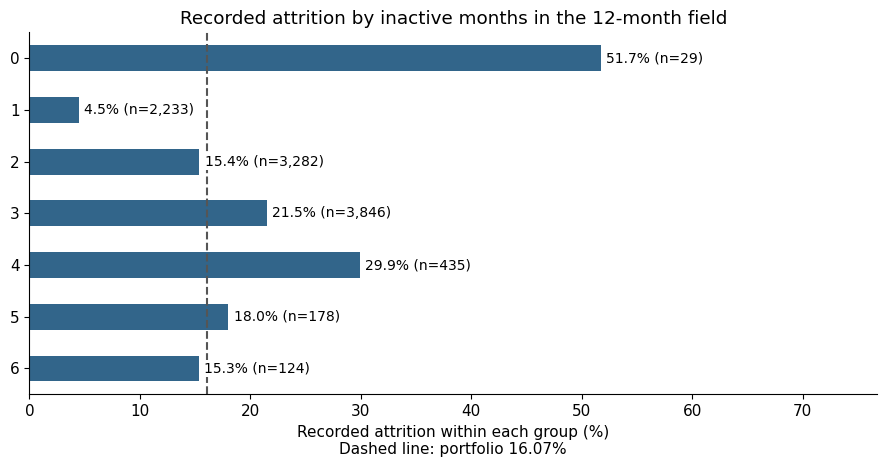

In [13]:
# Group customers and calculate customer counts and segment KPIs.
inactivity_segment = dl.groupby('Months_Inactive_12_mon').agg(
    Customers=('Churn_Flag', 'size'),
    Attrited=('Churn_Flag', 'sum'),
    Mean_transactions=('Total_Trans_Ct', 'mean'),
    Mean_transaction_amount=('Total_Trans_Amt', 'mean'),
    Mean_credit_limit=('Credit_Limit', 'mean'),
    Mean_utilisation=('Avg_Utilization_Ratio', 'mean'),
    Mean_relationships=('Total_Relationship_Count', 'mean')
)
inactivity_segment['Attrition_percent'] = inactivity_segment['Attrited'] / inactivity_segment['Customers'] * 100
inactivity_segment['Mean_utilisation'] = inactivity_segment['Mean_utilisation'] * 100
inactivity_segment = inactivity_segment.rename(columns={'Mean_utilisation': 'Mean_utilisation_percent'})
display(inactivity_segment.round(2))

# Compare percentages, keeping customer counts visible in labels.
ax = inactivity_segment['Attrition_percent'].plot.barh(figsize=(9, 4.8), color='#32658a')
ax.set_title('Recorded attrition by inactive months in the 12-month field')
ax.set_xlabel('Attrited customers within each group (%)')
ax.set_ylabel('')
ax.axvline(portfolio_attrition, color='#555555', linestyle='--', label='Portfolio proportion')
for position, (group, row) in enumerate(inactivity_segment.iterrows()):
    ax.text(row['Attrition_percent'] + 0.5, position,
            f"{row['Attrition_percent']:.1f}% (n={int(row['Customers']):,})", va='center', fontsize=10,
            bbox={'facecolor': 'white', 'edgecolor': 'none', 'pad': 1})
ax.set_xlim(0, max(50, inactivity_segment['Attrition_percent'].max() + 25))
ax.invert_yaxis()
# The dashed line marks the portfolio attrition proportion.
ax.set_xlabel(f'Recorded attrition within each group (%)\nDashed line: portfolio {portfolio_attrition:.2f}%')
plt.tight_layout()
plt.savefig(output_folder / '05_inactivity_segment.png', dpi=150)
plt.show()

**My interpretation**

The groups with one, two, three, and four inactive months have recorded attrition of 4.48%, 15.39%, 21.48%, and 29.89%. However, the pattern does not rise consistently across all groups. Zero inactive months has 51.72% attrition among only 29 customers, while five and six months have lower proportions than four. I therefore avoid the claim that every additional inactive month increases attrition.

## 14 Examine product relationships

I calculate the same KPIs within each group. The attrition percentage uses the group customer count as its denominator, so it can be compared across differently sized segments. Monetary measures retain the original units.

,Customers,Attrited,Mean_transactions,Mean_transaction_amount,Mean_credit_limit,Mean_utilisation_percent,Mean_relationships,Attrition_percent
Total_Relationship_Count,,,,,,,,
1,910,233,79.62,7252.92,10185.73,24.58,1.0,25.60
2,1243,346,77.08,7019.15,10294.09,23.07,2.0,27.84
3,2305,400,62.11,3936.28,8311.22,27.13,3.0,17.35
4,1912,225,61.75,3754.97,8212.21,28.77,4.0,11.77
5,1891,227,60.81,3515.33,7945.19,29.31,5.0,12.00
6,1866,196,60.20,3416.45,8289.26,29.14,6.0,10.50


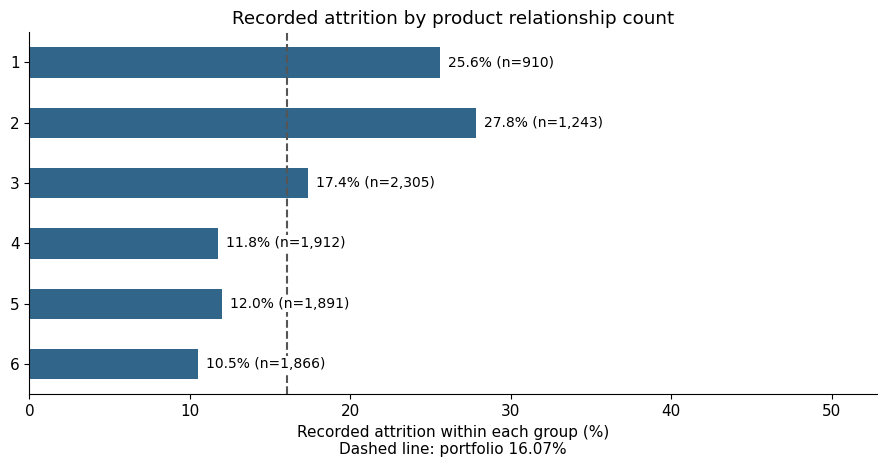

In [14]:
# Group customers and calculate customer counts and segment KPIs.
relationship_segment = dl.groupby('Total_Relationship_Count').agg(
    Customers=('Churn_Flag', 'size'),
    Attrited=('Churn_Flag', 'sum'),
    Mean_transactions=('Total_Trans_Ct', 'mean'),
    Mean_transaction_amount=('Total_Trans_Amt', 'mean'),
    Mean_credit_limit=('Credit_Limit', 'mean'),
    Mean_utilisation=('Avg_Utilization_Ratio', 'mean'),
    Mean_relationships=('Total_Relationship_Count', 'mean')
)
relationship_segment['Attrition_percent'] = relationship_segment['Attrited'] / relationship_segment['Customers'] * 100
relationship_segment['Mean_utilisation'] = relationship_segment['Mean_utilisation'] * 100
relationship_segment = relationship_segment.rename(columns={'Mean_utilisation': 'Mean_utilisation_percent'})
display(relationship_segment.round(2))

# Compare percentages, keeping customer counts visible in labels.
ax = relationship_segment['Attrition_percent'].plot.barh(figsize=(9, 4.8), color='#32658a')
ax.set_title('Recorded attrition by product relationship count')
ax.set_xlabel('Attrited customers within each group (%)')
ax.set_ylabel('')
ax.axvline(portfolio_attrition, color='#555555', linestyle='--', label='Portfolio proportion')
for position, (group, row) in enumerate(relationship_segment.iterrows()):
    ax.text(row['Attrition_percent'] + 0.5, position,
            f"{row['Attrition_percent']:.1f}% (n={int(row['Customers']):,})", va='center', fontsize=10,
            bbox={'facecolor': 'white', 'edgecolor': 'none', 'pad': 1})
ax.set_xlim(0, max(50, relationship_segment['Attrition_percent'].max() + 25))
ax.invert_yaxis()
# The dashed line marks the portfolio attrition proportion.
ax.set_xlabel(f'Recorded attrition within each group (%)\nDashed line: portfolio {portfolio_attrition:.2f}%')
plt.tight_layout()
plt.savefig(output_folder / '06_relationship_segment.png', dpi=150)
plt.show()

**My interpretation**

Customers with one or two relationships have attrition of 25.60% and 27.84%. Customers with four, five, and six relationships have 11.77%, 12.00%, and 10.50%. Fewer recorded relationships are associated with higher attrition, but this does not prove that selling another product would prevent leaving.

## 15 Examine recorded contacts

I calculate the same KPIs within each group. The attrition percentage uses the group customer count as its denominator, so it can be compared across differently sized segments. Monetary measures retain the original units.

,Customers,Attrited,Mean_transactions,Mean_transaction_amount,Mean_credit_limit,Mean_utilisation_percent,Mean_relationships,Attrition_percent
Contacts_Count_12_mon,,,,,,,,
0,399,7,58.80,3450.95,8104.39,29.29,4.20,1.75
1,1499,108,75.05,5523.41,8380.12,29.25,3.46,7.20
2,3227,403,65.32,4498.28,8748.76,28.11,3.85,12.49
3,3380,681,64.34,4407.34,8489.20,27.24,3.75,20.15
4,1392,315,57.26,3335.25,8904.62,25.88,4.16,22.63
5,176,59,57.22,3897.12,9835.55,19.19,4.00,33.52
6,54,54,52.69,3747.39,10524.49,11.99,3.31,100.00


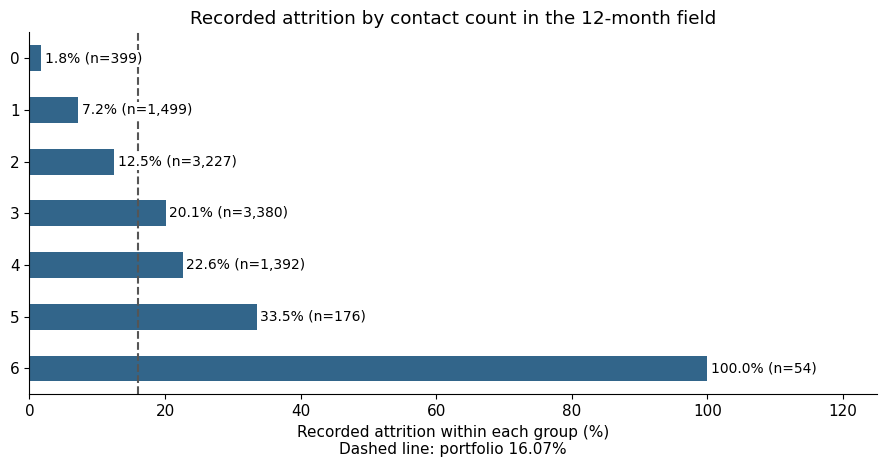

In [15]:
# Group customers and calculate customer counts and segment KPIs.
contact_segment = dl.groupby('Contacts_Count_12_mon').agg(
    Customers=('Churn_Flag', 'size'),
    Attrited=('Churn_Flag', 'sum'),
    Mean_transactions=('Total_Trans_Ct', 'mean'),
    Mean_transaction_amount=('Total_Trans_Amt', 'mean'),
    Mean_credit_limit=('Credit_Limit', 'mean'),
    Mean_utilisation=('Avg_Utilization_Ratio', 'mean'),
    Mean_relationships=('Total_Relationship_Count', 'mean')
)
contact_segment['Attrition_percent'] = contact_segment['Attrited'] / contact_segment['Customers'] * 100
contact_segment['Mean_utilisation'] = contact_segment['Mean_utilisation'] * 100
contact_segment = contact_segment.rename(columns={'Mean_utilisation': 'Mean_utilisation_percent'})
display(contact_segment.round(2))

# Compare percentages, keeping customer counts visible in labels.
ax = contact_segment['Attrition_percent'].plot.barh(figsize=(9, 4.8), color='#32658a')
ax.set_title('Recorded attrition by contact count in the 12-month field')
ax.set_xlabel('Attrited customers within each group (%)')
ax.set_ylabel('')
ax.axvline(portfolio_attrition, color='#555555', linestyle='--', label='Portfolio proportion')
for position, (group, row) in enumerate(contact_segment.iterrows()):
    ax.text(row['Attrition_percent'] + 0.5, position,
            f"{row['Attrition_percent']:.1f}% (n={int(row['Customers']):,})", va='center', fontsize=10,
            bbox={'facecolor': 'white', 'edgecolor': 'none', 'pad': 1})
ax.set_xlim(0, max(50, contact_segment['Attrition_percent'].max() + 25))
ax.invert_yaxis()
# The dashed line marks the portfolio attrition proportion.
ax.set_xlabel(f'Recorded attrition within each group (%)\nDashed line: portfolio {portfolio_attrition:.2f}%')
plt.tight_layout()
plt.savefig(output_folder / '07_contact_segment.png', dpi=150)
plt.show()

**My interpretation**

Recorded attrition rises across the contact-count groups: 1.75% at zero contacts, 20.15% at three, and 33.52% at five. All 54 customers with six contacts are labelled attrited. That small extreme group warrants investigation; it is not proof that contact causes attrition. Contacts are not verified complaints and could include cancellation-related interactions.

## 16 Compare age segments

I calculate the same KPIs within each group. The attrition percentage uses the group customer count as its denominator, so it can be compared across differently sized segments. Monetary measures retain the original units.

In [16]:
# Group customers and calculate customer counts and segment KPIs.
age_segment = dl.groupby('Age_Band').agg(
    Customers=('Churn_Flag', 'size'),
    Attrited=('Churn_Flag', 'sum'),
    Mean_transactions=('Total_Trans_Ct', 'mean'),
    Mean_transaction_amount=('Total_Trans_Amt', 'mean'),
    Mean_credit_limit=('Credit_Limit', 'mean'),
    Mean_utilisation=('Avg_Utilization_Ratio', 'mean'),
    Mean_relationships=('Total_Relationship_Count', 'mean')
)
age_segment = age_segment.reindex(['Under 35', '35 to 44', '45 to 54', '55 to 64', '65 and above'])
age_segment['Attrition_percent'] = age_segment['Attrited'] / age_segment['Customers'] * 100
age_segment['Mean_utilisation'] = age_segment['Mean_utilisation'] * 100
age_segment = age_segment.rename(columns={'Mean_utilisation': 'Mean_utilisation_percent'})
display(age_segment.round(2))

,Customers,Attrited,Mean_transactions,Mean_transaction_amount,Mean_credit_limit,Mean_utilisation_percent,Mean_relationships,Attrition_percent
Age_Band,,,,,,,,
Under 35,735,101,65.62,4707.08,7242.80,29.87,3.88,13.74
35 to 44,3440,548,65.55,4420.86,8777.00,26.89,3.84,15.93
45 to 54,4342,716,66.29,4533.79,9135.45,26.71,3.75,16.49
55 to 64,1499,251,59.72,3972.25,7744.57,29.56,3.88,16.74
65 and above,111,11,51.98,2635.98,5623.79,32.68,4.17,9.91


**My interpretation**

Attrition proportions across the large 35 to 64 groups are similar, ranging from 15.93% to 16.74%. Under-35 customers have 13.74%, while customers aged 65 and above have 9.91% based on only 111 records. Age differences are smaller than the transaction-frequency differences, and the oldest group is relatively small.

## 17 Compare income segments

I calculate the same KPIs within each group. The attrition percentage uses the group customer count as its denominator, so it can be compared across differently sized segments. Monetary measures retain the original units.

In [17]:
# Group customers and calculate customer counts and segment KPIs.
income_segment = dl.groupby('Income_Segment').agg(
    Customers=('Churn_Flag', 'size'),
    Attrited=('Churn_Flag', 'sum'),
    Mean_transactions=('Total_Trans_Ct', 'mean'),
    Mean_transaction_amount=('Total_Trans_Amt', 'mean'),
    Mean_credit_limit=('Credit_Limit', 'mean'),
    Mean_utilisation=('Avg_Utilization_Ratio', 'mean'),
    Mean_relationships=('Total_Relationship_Count', 'mean')
)
income_segment = income_segment.reindex(['Below $40K', '$40K to below $80K', '$80K and above', 'Unknown'])
income_segment['Attrition_percent'] = income_segment['Attrited'] / income_segment['Customers'] * 100
income_segment['Mean_utilisation'] = income_segment['Mean_utilisation'] * 100
income_segment = income_segment.rename(columns={'Mean_utilisation': 'Mean_utilisation_percent'})
display(income_segment.round(2))

,Customers,Attrited,Mean_transactions,Mean_transaction_amount,Mean_credit_limit,Mean_utilisation_percent,Mean_relationships,Attrition_percent
Income_Segment,,,,,,,,
Below $40K,3561,612,66.15,4363.42,3754.40,37.73,3.82,17.19
$40K to below $80K,3192,460,64.23,4425.43,7788.61,26.80,3.81,14.41
$80K and above,2262,368,63.02,4497.91,17065.73,15.00,3.80,16.27
Unknown,1112,187,66.25,4282.21,9516.58,22.08,3.81,16.82


**My interpretation**

The below-$40K group has 17.19% recorded attrition, compared with 14.41% in the $40K-to-below-$80K group and 16.27% in the $80K-and-above group. Unknown income has 16.82%. The differences are modest compared with transaction-frequency differences. I retain Unknown rather than assign guessed income, and do not infer that income causes leaving.

## 18 Compare card categories

I calculate the same KPIs within each group. The attrition percentage uses the group customer count as its denominator, so it can be compared across differently sized segments. Monetary measures retain the original units.

In [18]:
# Group customers and calculate customer counts and segment KPIs.
card_segment = dl.groupby('Card_Category').agg(
    Customers=('Churn_Flag', 'size'),
    Attrited=('Churn_Flag', 'sum'),
    Mean_transactions=('Total_Trans_Ct', 'mean'),
    Mean_transaction_amount=('Total_Trans_Amt', 'mean'),
    Mean_credit_limit=('Credit_Limit', 'mean'),
    Mean_utilisation=('Avg_Utilization_Ratio', 'mean'),
    Mean_relationships=('Total_Relationship_Count', 'mean')
)
card_segment = card_segment.reindex(['Blue', 'Silver', 'Gold', 'Platinum'])
card_segment['Attrition_percent'] = card_segment['Attrited'] / card_segment['Customers'] * 100
card_segment['Mean_utilisation'] = card_segment['Mean_utilisation'] * 100
card_segment = card_segment.rename(columns={'Mean_utilisation': 'Mean_utilisation_percent'})
display(card_segment.round(2))

,Customers,Attrited,Mean_transactions,Mean_transaction_amount,Mean_credit_limit,Mean_utilisation_percent,Mean_relationships,Attrition_percent
Card_Category,,,,,,,,
Blue,9436,1519,64.03,4225.41,7363.78,29.09,3.85,16.10
Silver,555,82,74.70,6590.48,25277.84,5.73,3.42,14.77
Gold,116,21,81.52,7685.61,28416.37,5.71,3.01,18.10
Platinum,20,5,86.95,8999.75,30283.45,4.36,2.30,25.00


**My interpretation**

Blue cards account for 9,436 customers and 1,519 attrited records, so they dominate attrition counts. Their attrition proportion is 16.10%. Platinum has 25.00% but only five attrited customers out of 20. I would not prioritise Platinum solely because it has the highest percentage. Group size and the absolute number of affected customers both matter.

## 19 Summarise the main patterns

I bring the observations together and state the limits of each explanation.

In [19]:
pattern_summary = pd.DataFrame({
    'Observed pattern': ['Lower transaction activity', 'Zero utilisation', 'Fewer product relationships', 'More recorded contacts', 'Inactivity with exceptions'],
    'Evidence': ['38.00% attrition below 50 transactions versus 1.32% at 80 or more',
        '36.15% attrition with zero utilisation versus 8.08% to 10.20% in nonzero groups',
        '25.60% to 27.84% with 1 to 2 relationships versus 10.50% to 12.00% with 4 to 6',
        '20.15% with 3 contacts; 33.52% with 5; 100% with 6 contacts (n=54)',
        '4.48% with 1 inactive month; 29.89% with 4, but not a consistent rise'],
    'Interpretation limit': ['Lower activity may precede or follow leaving.',
        'Zero balance may reflect account closure.', 'More products have not been shown to cause retention.',
        'Contacts are not confirmed complaints or service-quality scores.',
        'Small groups and irregular patterns limit a simple trend claim.']
})
display(pattern_summary)

,Observed pattern,Evidence,Interpretation limit
0,Lower transaction activity,38.00% attrition below 50 transactions versus ...,Lower activity may precede or follow leaving.
1,Zero utilisation,36.15% attrition with zero utilisation versus ...,Zero balance may reflect account closure.
2,Fewer product relationships,25.60% to 27.84% with 1 to 2 relationships ver...,More products have not been shown to cause ret...
3,More recorded contacts,20.15% with 3 contacts; 33.52% with 5; 100% wi...,Contacts are not confirmed complaints or servi...
4,Inactivity with exceptions,"4.48% with 1 inactive month; 29.89% with 4, bu...",Small groups and irregular patterns limit a si...


**My interpretation**

I identify five patterns, exceeding the requirement for three. Recorded usage and engagement show substantial differences, while demographic differences are smaller in the examined cuts. These findings support targeted investigation, not causal claims. I have not tested independent effects or statistical significance.

## 20 Define a simple retention review score

I assign one point for each of three conditions:

| Rule | Point | Reason for including it |
|---|---:|---|
| Fewer than 50 recorded transactions | 1 | Reuses the Low transaction group from Task 2, which has higher observed attrition. |
| At least 3 inactive months in the recorded 12-month field | 1 | Represents reduced engagement; the detailed inactivity pattern contains exceptions. |
| No more than 2 product relationships | 1 | Identifies the two relationship groups with higher observed attrition. |

A score of **0 is Low**, **1 is Medium**, and **2 or 3 is High**. These are relative review bands, not calibrated probabilities. The three rules have equal weights for transparency, not because equal predictive importance has been established.

I selected these rules while exploring this same file. Assessing the bands against recorded attrition is therefore an **in-sample descriptive check**, not independent validation. The rules do not use customer status, Churn_Flag, identifiers, demographic attributes, or the removed classifier outputs. Some behavioural measurements may nevertheless reflect the attrition process itself. Before operational use, the bank would need measurements taken before a defined future outcome and validation on later customers. I exclude zero utilisation and contact count from the score because their timing and meaning require particular caution.

## 21 Calculate the score and review bands

Each true condition becomes 1 and each false condition becomes 0. I add the three flags and map the result to the defined band.

In [20]:
dl['Low_Transaction_Flag'] = (dl['Total_Trans_Ct'] < 50).astype(int)
dl['Inactivity_Flag'] = (dl['Months_Inactive_12_mon'] >= 3).astype(int)
dl['Few_Relationships_Flag'] = (dl['Total_Relationship_Count'] <= 2).astype(int)

dl['Retention_Review_Score'] = (
    dl['Low_Transaction_Flag'] + dl['Inactivity_Flag'] + dl['Few_Relationships_Flag']
)
dl['Retention_Risk_Band'] = dl['Retention_Review_Score'].map({0: 'Low', 1: 'Medium', 2: 'High', 3: 'High'})

score_counts = dl['Retention_Review_Score'].value_counts().sort_index()
display(score_counts.to_frame('Customers'))
print('Rules applied without using the recorded outcome.')

Rules applied without using the recorded outcome.


,Customers
Retention_Review_Score,
0,2963
1,4817
2,2085
3,262


**My interpretation**

Every customer receives an interpretable score from zero to three. The flags explain which conditions contributed to the score. Low does not mean no risk, and High does not mean that a customer will leave.

## 22 Describe recorded attrition within score bands

I compare the review bands with known customer status after assigning scores. This describes separation in this sample; it does not estimate future predictive accuracy.

,Customers,Attrited,Existing,Observed_attrition_percent
Retention_Risk_Band,,,,
Low,2963,90,2873,3.04
Medium,4817,574,4243,11.92
High,2347,963,1384,41.03


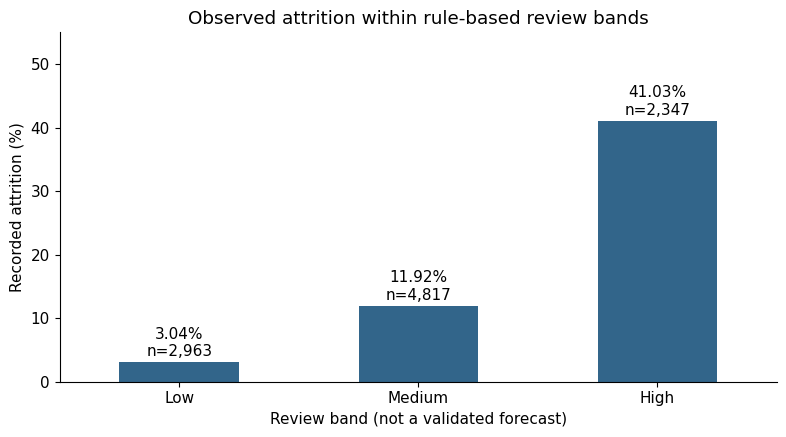

In [21]:
band_order = ['Low', 'Medium', 'High']
risk_summary = dl.groupby('Retention_Risk_Band').agg(
    Customers=('Churn_Flag', 'size'), Attrited=('Churn_Flag', 'sum')
).reindex(band_order)
risk_summary['Existing'] = risk_summary['Customers'] - risk_summary['Attrited']
risk_summary['Observed_attrition_percent'] = risk_summary['Attrited'] / risk_summary['Customers'] * 100
display(risk_summary.round(2))

ax = risk_summary['Observed_attrition_percent'].plot.bar(figsize=(8, 4.5), color='#32658a', rot=0)
ax.set_title('Observed attrition within rule-based review bands')
ax.set_xlabel('Review band (not a validated forecast)')
ax.set_ylabel('Recorded attrition (%)')
ax.set_ylim(0, 55)
for position, row in enumerate(risk_summary.itertuples()):
    ax.text(position, row.Observed_attrition_percent + 1,
            f'{row.Observed_attrition_percent:.2f}%\nn={row.Customers:,}', ha='center')
plt.tight_layout()
plt.savefig(output_folder / '08_Review_Band_Attrition.png', dpi=150)
plt.show()

**My interpretation**

Low contains 2,963 customers with 3.04% recorded attrition; Medium contains 4,817 with 11.92%; High contains 2,347 with 41.03%. The High group includes 963 attrited customers and 1,384 existing customers. Another 664 attrited customers are outside High, so the rules miss some historical attrition. These proportions come from the same file used to choose the rules and must not be presented as validated future probabilities.

## 23 Focus retention review on existing customers

Customers already labelled attrited are not the same operational group as existing customers who could receive preventive support. I separate them before presenting a retention review list.

In [22]:
existing_dl = dl.loc[dl['Churn_Flag'] == 0].copy()
existing_bands = existing_dl['Retention_Risk_Band'].value_counts().reindex(band_order, fill_value=0).to_frame('Existing_customers')
existing_bands['Percent_of_existing'] = existing_bands['Existing_customers'] / len(existing_dl) * 100
display(existing_bands.round(2))

# Export flags for investigation, not an automatic campaign or adverse decision.
review_columns = ['CLIENTNUM', 'Retention_Review_Score', 'Retention_Risk_Band',
    'Low_Transaction_Flag', 'Inactivity_Flag', 'Few_Relationships_Flag',
    'Total_Trans_Ct', 'Months_Inactive_12_mon', 'Total_Relationship_Count']
high_review_customers = existing_dl.loc[existing_dl['Retention_Risk_Band'] == 'High', review_columns]
print('Existing customers in the High review band:', len(high_review_customers))
# Do not display individual identifiers in the notebook.

Existing customers in the High review band: 1384


,Existing_customers,Percent_of_existing
Retention_Risk_Band,,
Low,2873,33.80
Medium,4243,49.92
High,1384,16.28


**My interpretation**

Of the 8,500 existing customers, 2,873 are Low (33.80%), 4,243 are Medium (49.92%), and 1,384 are High (16.28%). The High band gives management a defined group for further review, not a list of certain future churners. Any outreach would need appropriate permissions, a pilot, and an outcome evaluation; I do not contact customers or change credit decisions.

## 24 Check sensitivity to the transaction threshold

A score based on chosen cut-offs can change when a cut-off changes. I vary the transaction threshold while keeping the other two rules and the band definitions unchanged.

In [23]:
sensitivity_rows = []
for threshold in [40, 50, 60]:
    temporary_score = (
        (dl['Total_Trans_Ct'] < threshold).astype(int)
        + dl['Inactivity_Flag'] + dl['Few_Relationships_Flag']
    )
    high_flag = temporary_score >= 2
    sensitivity_rows.append({
        'Transaction_threshold_below': threshold,
        'All_customers_in_High': int(high_flag.sum()),
        'Existing_customers_in_High': int((high_flag & dl['Churn_Flag'].eq(0)).sum()),
        'Observed_attrition_in_High_percent': dl.loc[high_flag, 'Churn_Flag'].mean() * 100
    })
sensitivity_table = pd.DataFrame(sensitivity_rows)
display(sensitivity_table.round(2))

,Transaction_threshold_below,All_customers_in_High,Existing_customers_in_High,Observed_attrition_in_High_percent
0,40,1761,1117,36.57
1,50,2347,1384,41.03
2,60,2767,1682,39.21


**My interpretation**

A below-40 threshold puts 1,117 existing customers in High, compared with 1,384 below 50 and 1,682 below 60. Historical attrition within the corresponding High groups is 36.57%, 41.03%, and 39.21%. These differences show that both workload and group composition depend on the chosen rule. This sensitivity check is not threshold optimisation or validation. I keep the below-50 rule for consistency with Task 2 and transparent explanation, rather than claim it is an optimal business threshold.

## 25 Export the analysis for Power BI

I export the customer-level data with five new review fields and the summary tables. The customer export includes all recorded statuses; Power BI should filter existing customers when showing preventive review workload.

In [24]:
review_fields = ['Low_Transaction_Flag', 'Inactivity_Flag', 'Few_Relationships_Flag',
                 'Retention_Review_Score', 'Retention_Risk_Band']
review_definitions = pd.DataFrame({
    'Field': review_fields,
    'Definition': ['1 if Total_Trans_Ct < 50; otherwise 0',
        '1 if Months_Inactive_12_mon >= 3; otherwise 0',
        '1 if Total_Relationship_Count <= 2; otherwise 0',
        'Sum of the three condition flags; range 0 to 3',
        'Low=0 points; Medium=1; High=2 or 3. Review bands, not validated probabilities.']
})
analysis_file = output_folder / 'BankChurners_Task3_Analysis.csv'
dl.to_csv(analysis_file, index=False)
high_review_customers.to_csv(output_folder / 'Existing_Customers_High_Review.csv', index=False)
portfolio_kpis.to_csv(output_folder / 'Portfolio_KPIs.csv', index=False)
kpi_definitions.to_csv(output_folder / 'KPI_Definitions.csv', index=False)
summary_statistics.to_csv(output_folder / 'Summary_Statistics.csv')
mean_comparison.to_csv(output_folder / 'Status_Means.csv')
median_comparison.to_csv(output_folder / 'Status_Medians.csv')
risk_summary.to_csv(output_folder / 'Review_Band_Summary.csv')
existing_bands.to_csv(output_folder / 'Existing_Customer_Review_Bands.csv')
sensitivity_table.to_csv(output_folder / 'Rule_Sensitivity.csv', index=False)
review_definitions.to_csv(output_folder / 'Review_Field_Definitions.csv', index=False)
pattern_summary.to_csv(output_folder / 'Observed_Patterns.csv', index=False)
# Export the customer segment tables calculated earlier.
segment_tables = {
    'Transactions': transaction_segment, 'Utilisation': utilisation_segment,
    'Inactivity': inactivity_segment, 'Relationships': relationship_segment,
    'Contacts': contact_segment, 'Age': age_segment, 'Income': income_segment, 'Cards': card_segment
}
for name, table in segment_tables.items():
    table.to_csv(output_folder / f'Segment_{name}.csv')
print('Analysis data exported:', analysis_file)
print('Customer rows:', len(dl), '| Columns:', dl.shape[1])

Analysis data exported: /workspace/scratch/8d55d39321ed/upload/Task3_Outputs/BankChurners_Task3_Analysis.csv
Customer rows: 10127 | Columns: 32


**My interpretation**

The Power BI input contains 10,127 rows and 32 columns: the 27 cleaned fields plus five review fields. The separate High-review file contains only 1,384 existing customers. I retain CLIENTNUM only for record handling; access to customer-level lists should be restricted. Summary tables and rules are exported so the calculations can be checked.

## 26 Verify the saved analysis

I confirm that Task 3 preserved the cleaned source fields and that the saved output has the same scores and labels.

In [25]:
pd.testing.assert_frame_equal(dl[source_dl.columns], source_dl)
assert dl[review_fields].notna().all().all()
assert dl['Retention_Review_Score'].between(0, 3).all()
assert risk_summary['Customers'].sum() == total_customers
assert risk_summary['Attrited'].sum() == attrited_customers
assert existing_bands['Existing_customers'].sum() == existing_customers
for name, table in segment_tables.items():
    assert table['Customers'].sum() == total_customers
    assert table['Attrited'].sum() == attrited_customers

saved_dl = pd.read_csv(analysis_file, dtype={'CLIENTNUM': str})
assert saved_dl.shape == dl.shape
assert saved_dl['CLIENTNUM'].equals(dl['CLIENTNUM'])
for column in review_fields + ['Churn_Flag']:
    assert saved_dl[column].equals(dl[column])
print('All verification checks passed.')

All verification checks passed.


**My interpretation**

All source fields remain unchanged. Segment totals reconcile to the full portfolio, and the customer counts, outcomes, scores, and bands match the saved analysis file. No original customers were dropped.

## Conclusions and practical limits

I compared eight measurements across customer statuses and calculated KPIs for eight customer segment definitions. Lower transaction activity, zero utilisation, fewer relationships, recorded contact patterns, and inactivity differences are associated with attrition. The behaviour patterns are useful for investigation, but do not establish why individual customers left.

My score meets the requirement for Low, Medium, and High retention review groups using simple, inspectable rules. The High band includes 1,384 existing customers. Before using it operationally, I would require dated predictors measured before the outcome, later-period validation, threshold selection based on capacity and costs, and checks for unequal effects across customer groups. Excluding demographics from the score does not guarantee fairness because behavioural features can still be associated with demographics.

I would use the findings to plan a limited retention pilot, not automatically change credit limits, deny services, or assume that contact frequency means complaints. A later evaluation would compare future outcomes with a suitable comparison group.

### Sources
Input: the supplied cleaned BankChurners CSV and Task 2 notebook. I used their existing field definitions and did not add external customer data. Dataset source: Goyal, S. (n.d.). *Credit card customers* [Data set]. Kaggle. https://www.kaggle.com/datasets/sakshigoyal7/credit-card-customers

All reported percentages, tables, and charts were calculated from the supplied file. No claim of statistically significant differences or validated forecasting performance is made.